Mounted at /content/drive
Đã kết nối thư mục gốc: /content/drive/MyDrive/BTL_46_Heart_Disease


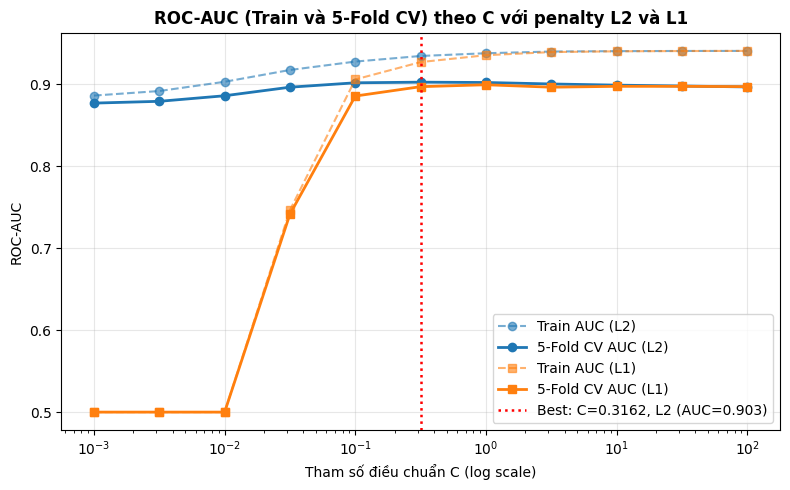

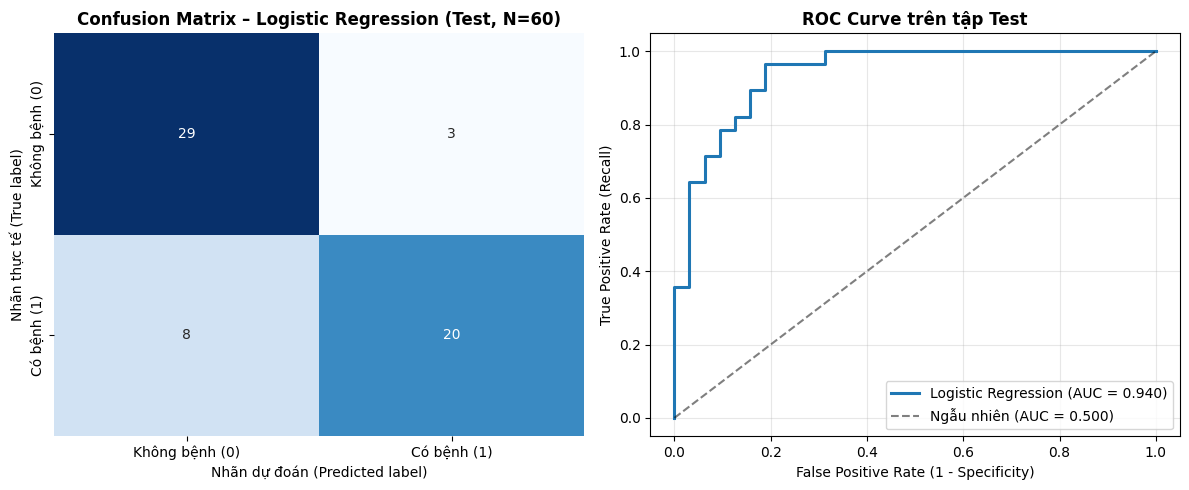

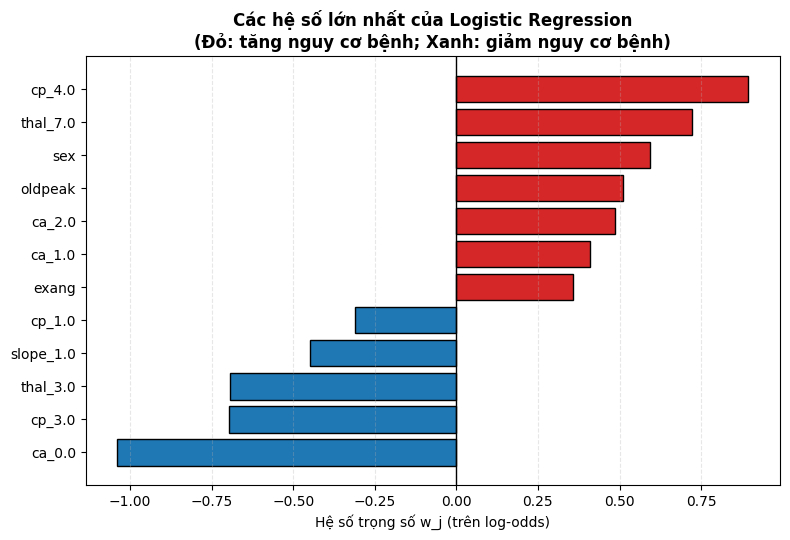


ĐIỀN CÁC Ô TÔ VÀNG [[..]] TRONG MỤC 3 (Phan_TV5_Logistic_va_Tong_hop.docx):
- Đoạn đầu Mục 3: Với tham số mặc định (C = 1, L2), ROC-AUC trung bình 5-fold đạt 0.902 ± 0.070. Sau khi tune, cấu hình tốt nhất là C = 0.3162, penalty = 'l2', đạt ROC-AUC = 0.903 ± 0.072 (Bảng 1).

- Bảng 1 (làm tròn 3 chữ số):
  Accuracy   | CV: 0.835 | Std: 0.080 | Test: 0.817
  Precision  | CV: 0.851 | Std: 0.096 | Test: 0.870
  Recall     | CV: 0.787 | Std: 0.111 | Test: 0.714
  F1-score   | CV: 0.813 | Std: 0.087 | Test: 0.784
  ROC-AUC    | CV: 0.903 | Std: 0.072 | Test: 0.940

- Dưới Hình 1: Chênh lệch Train–CV ROC-AUC ở cấu hình tốt nhất là 0.032 điểm (Train AUC = 0.935, CV AUC = 0.903).
- Dưới Hình 2: Trên 60 mẫu Test, ma trận nhầm lẫn có TN = 29, FP = 3, FN = 8, TP = 20; Recall = 0.714 (bỏ sót 8/28 ca bệnh) và Specificity = 0.906.
- Dưới Hình 3 (Top 5 đặc trưng): ca_0.0 (w = -1.04, OR = 0.35), cp_4.0 (w = +0.90, OR = 2.45), thal_7.0 (w = +0.72, OR = 2.06), cp_3.0 (w = -0.70, OR = 0.50), thal_3.0 (w 

In [2]:
from google.colab import drive
import os, glob, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# 1. MOUNT DRIVE & TỰ ĐỘNG ĐỊNH VỊ THƯ MỤC BTL_46_Heart_Disease
drive.mount('/content/drive')

possible_paths = glob.glob('/content/drive/**/BTL_46_Heart_Disease', recursive=True)
if not possible_paths:
    raise FileNotFoundError("Không tìm thấy thư mục BTL_46_Heart_Disease! Hãy tạo lối tắt (Add shortcut to Drive) thư mục nhóm vào MyDrive.")
BASE_DIR = possible_paths[0]
DATA_DIR = os.path.join(BASE_DIR, "00_Shared/data")
OUT_DIR  = os.path.join(BASE_DIR, "05_Logistic")
RES_DIR  = os.path.join(OUT_DIR, "result") # Lưu cả vào05_Logistic và 05_Logistic/result
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

print("Đã kết nối thư mục gốc:", BASE_DIR)

# 2. LOAD RAW DATA CHÍNH THỨC
X_train = pd.read_csv(os.path.join(DATA_DIR, "X_train_raw.csv"))
X_test  = pd.read_csv(os.path.join(DATA_DIR, "X_test_raw.csv"))
y_train = np.load(os.path.join(DATA_DIR, "y_train.npy"))
y_test  = np.load(os.path.join(DATA_DIR, "y_test.npy"))

# 3. TIỀN XỬ LÝ TRONG PIPELINE (Khớp 100% Mục 2 của Phan_TV5_Logistic_va_Tong_hop.docx)
RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
bin_cols = ["sex", "fbs", "exang"]
cat_cols = ["cp", "restecg", "slope", "ca", "thal"]

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), bin_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), cat_cols)
])

# 4. ĐÁNH GIÁ BASELINE MẶC ĐỊNH (C = 1, L2)
default_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(C=1.0, penalty="l2", solver="liblinear", max_iter=5000, random_state=RANDOM_STATE))
])
default_cv = cross_validate(default_pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
default_auc_mean = np.mean(default_cv["test_score"])
default_auc_std  = np.std(default_cv["test_score"])

# 5. GRIDSEARCHCV TUNE C VÀ PENALTY (11 giá trị C x 2 penalty = 22 cấu hình)
pipe_lr = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(solver="liblinear", max_iter=5000, random_state=RANDOM_STATE))
])

param_grid = {
    "clf__C": np.logspace(-3, 2, 11),
    "clf__penalty": ["l1", "l2"]
}

grid_lr = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    refit=True
)
grid_lr.fit(X_train, y_train)

best_lr = grid_lr.best_estimator_
best_C  = float(grid_lr.best_params_["clf__C"])
best_penalty = grid_lr.best_params_["clf__penalty"]
best_idx = grid_lr.best_index_
best_train_auc = grid_lr.cv_results_["mean_train_score"][best_idx]
best_cv_auc    = grid_lr.cv_results_["mean_test_score"][best_idx]
gap_train_cv   = best_train_auc - best_cv_auc

# 6. TÍNH ĐỦ 5 CHỈ SỐ CV TRÊN TRAIN & ĐÁNH GIÁ TRÊN TEST (60 MẪU)
scoring_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_res = cross_validate(best_lr, X_train, y_train, cv=cv, scoring=scoring_metrics, n_jobs=-1)

y_pred_lr  = best_lr.predict(X_test)
y_score_lr = best_lr.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_lr).ravel()
spec_test = tn / (tn + fp)

test_metrics = {
    "accuracy":  accuracy_score(y_test, y_pred_lr),
    "precision": precision_score(y_test, y_pred_lr),
    "recall":    recall_score(y_test, y_pred_lr),
    "f1":        f1_score(y_test, y_pred_lr),
    "roc_auc":   roc_auc_score(y_test, y_score_lr)
}

# 7. VẼ 3 HÌNH CHUẨN TÊN FILE TRONG BẢN NHÁP
cv_df = pd.DataFrame(grid_lr.cv_results_)

# --- HÌNH 1: LR_tuning_C.png ---
plt.figure(figsize=(8, 5))
for pen, color, marker in [("l2", "#1f77b4", "o"), ("l1", "#ff7f0e", "s")]:
    sub = cv_df[cv_df["param_clf__penalty"] == pen]
    plt.semilogx(sub["param_clf__C"], sub["mean_train_score"], linestyle="--", marker=marker, color=color, alpha=0.6, label=f"Train AUC ({pen.upper()})")
    plt.semilogx(sub["param_clf__C"], sub["mean_test_score"], linestyle="-", marker=marker, color=color, lw=2, label=f"5-Fold CV AUC ({pen.upper()})")
plt.axvline(best_C, color="red", linestyle=":", lw=1.8, label=f"Best: C={best_C:.4g}, {best_penalty.upper()} (AUC={best_cv_auc:.3f})")
plt.title("ROC-AUC (Train và 5-Fold CV) theo C với penalty L2 và L1", fontweight="bold")
plt.xlabel("Tham số điều chuẩn C (log scale)")
plt.ylabel("ROC-AUC")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
for d in [OUT_DIR, RES_DIR]:
    plt.savefig(os.path.join(d, "LR_tuning_C.png"), dpi=300)
plt.show()

# --- HÌNH 2: LR_roc_confusion.png ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Không bệnh (0)", "Có bệnh (1)"],
            yticklabels=["Không bệnh (0)", "Có bệnh (1)"])
axes[0].set_title(f"Confusion Matrix – Logistic Regression (Test, N=60)", fontweight="bold")
axes[0].set_xlabel("Nhãn dự đoán (Predicted label)")
axes[0].set_ylabel("Nhãn thực tế (True label)")

fpr, tpr, _ = roc_curve(y_test, y_score_lr)
axes[1].plot(fpr, tpr, lw=2.2, color="#1f77b4", label=f"Logistic Regression (AUC = {test_metrics['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Ngẫu nhiên (AUC = 0.500)")
axes[1].set_title("ROC Curve trên tập Test", fontweight="bold")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
for d in [OUT_DIR, RES_DIR]:
    plt.savefig(os.path.join(d, "LR_roc_confusion.png"), dpi=300)
plt.show()

# --- HÌNH 3: LR_coefficients.png ---
ohe_feature_names = best_lr.named_steps["prep"].named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(cat_cols)
all_feat_names = list(num_cols) + list(bin_cols) + list(ohe_feature_names)
coefs = best_lr.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({
    "Feature": all_feat_names,
    "Coef": coefs,
    "AbsCoef": np.abs(coefs),
    "OddsRatio": np.exp(coefs)
}).sort_values(by="AbsCoef", ascending=False)

top_coef = coef_df[coef_df["AbsCoef"] > 0].head(12).sort_values(by="Coef", ascending=True)
plt.figure(figsize=(8, 5.5))
colors = ["#d62728" if c > 0 else "#1f77b4" for c in top_coef["Coef"]]
plt.barh(top_coef["Feature"], top_coef["Coef"], color=colors, edgecolor="black")
plt.axvline(0, color="black", lw=1)
plt.title("Các hệ số lớn nhất của Logistic Regression\n(Đỏ: tăng nguy cơ bệnh; Xanh: giảm nguy cơ bệnh)", fontweight="bold")
plt.xlabel("Hệ số trọng số w_j (trên log-odds)")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
for d in [OUT_DIR, RES_DIR]:
    plt.savefig(os.path.join(d, "LR_coefficients.png"), dpi=300)
plt.show()

# 8. XUẤT FILE RESULT CHUẨN CONTRACT VÀO DRIVE
result_dict = {
    "Model": "Logistic Regression",
    "Accuracy_mean": round(float(np.mean(cv_res["test_accuracy"])), 4),
    "Accuracy_std":  round(float(np.std(cv_res["test_accuracy"])), 4),
    "Precision_mean": round(float(np.mean(cv_res["test_precision"])), 4),
    "Recall_mean":    round(float(np.mean(cv_res["test_recall"])), 4),
    "F1_mean":        round(float(np.mean(cv_res["test_f1"])), 4),
    "ROC_AUC_mean":   round(float(np.mean(cv_res["test_roc_auc"])), 4),
    "Best_params": {"C": round(best_C, 4), "penalty": best_penalty},
    "Note": (
        f"Logistic Regression (solver=liblinear); tune C va penalty theo ROC-AUC bang 5-Fold Stratified CV. "
        f"Test (N=60): Acc={test_metrics['accuracy']:.4f}, Prec={test_metrics['precision']:.4f}, "
        f"Rec={test_metrics['recall']:.4f}, F1={test_metrics['f1']:.4f}, AUC={test_metrics['roc_auc']:.4f}. "
        f"y_score = predict_proba (lop benh=1)."
    )
}

for d in [OUT_DIR, RES_DIR]:
    with open(os.path.join(d, "LR_result.json"), "w", encoding="utf-8") as f:
        json.dump(result_dict, f, indent=4, ensure_ascii=False)
    np.save(os.path.join(d, "y_pred_LR.npy"), y_pred_lr)
    np.save(os.path.join(d, "y_score_LR.npy"), y_score_lr)
    joblib.dump(best_lr, os.path.join(d, "best_lr_pipeline.joblib"))

# 9. IN RA SỐ LIỆU ĐỂ COPY-PASTE VÀO CÁC Ô [[..]] MỤC 3 TRONG FILE WORD
print("\n" + "="*70)
print("ĐIỀN CÁC Ô TÔ VÀNG [[..]] TRONG MỤC 3 (Phan_TV5_Logistic_va_Tong_hop.docx):")
print("="*70)
print(f"- Đoạn đầu Mục 3: Với tham số mặc định (C = 1, L2), ROC-AUC trung bình 5-fold đạt {default_auc_mean:.3f} ± {default_auc_std:.3f}. Sau khi tune, cấu hình tốt nhất là C = {best_C:.4g}, penalty = '{best_penalty}', đạt ROC-AUC = {result_dict['ROC_AUC_mean']:.3f} ± { np.std(cv_res['test_roc_auc']):.3f} (Bảng 1).")
print("\n- Bảng 1 (làm tròn 3 chữ số):")
for m_name, key in [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall", "recall"), ("F1-score", "f1"), ("ROC-AUC", "roc_auc")]:
    m_val = np.mean(cv_res[f"test_{key}"])
    s_val = np.std(cv_res[f"test_{key}"])
    t_val = test_metrics[key]
    print(f"  {m_name:10s} | CV: {m_val:.3f} | Std: {s_val:.3f} | Test: {t_val:.3f}")

print(f"\n- Dưới Hình 1: Chênh lệch Train–CV ROC-AUC ở cấu hình tốt nhất là {gap_train_cv:.3f} điểm (Train AUC = {best_train_auc:.3f}, CV AUC = {best_cv_auc:.3f}).")
print(f"- Dưới Hình 2: Trên 60 mẫu Test, ma trận nhầm lẫn có TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}; Recall = {test_metrics['recall']:.3f} (bỏ sót {fn}/28 ca bệnh) và Specificity = {spec_test:.3f}.")
top5_str = ", ".join([f"{r.Feature} (w = {r.Coef:+.2f}, OR = {r.OddsRatio:.2f})" for _, r in coef_df.head(5).iterrows()])
print(f"- Dưới Hình 3 (Top 5 đặc trưng): {top5_str}")